# Proyek Analisis Data: E-Commerce Public Dataset
- **Nama:** Wiola Derul Rahayu
- **Email:** wiola.22092@mhs.unesa.ac.id
- **ID Dicoding:** wiola_derul_rahayu

## Menentukan Pertanyaan Bisnis

- Bagaimana demografi penjual berdasarkan wilayah penjual?
- Berapa hari keterlambatan pengiriman untuk setiap order dalam 50 pesanan terakhir yang berhasil terkirim?

## Import Semua Packages/Library yang Digunakan

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Data Wrangling

### Gathering Data

In [5]:
#Memuat tabel sellers
sellers_df = pd.read_csv("sellers_dataset.csv")
sellers_df.head()

,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP


In [6]:
#Memuat tabel orders
orders_df = pd.read_csv("orders_dataset.csv")
orders_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


**Insight:**
- Berhasil memuat data sellers
- Berhasil memuat data orders

### Assessing Data

In [7]:
#Menilai data sellers_df
#Menampilkan data sellers_df
sellers_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3095 entries, 0 to 3094
Data columns (total 4 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   seller_id               3095 non-null   object
 1   seller_zip_code_prefix  3095 non-null   int64 
 2   seller_city             3095 non-null   object
 3   seller_state            3095 non-null   object
dtypes: int64(1), object(3)
memory usage: 96.8+ KB


In [8]:
#Memeriksa jumlah missing values pada data sellers_df
sellers_df.isna().sum()

,0
seller_id,0
seller_zip_code_prefix,0
seller_city,0
seller_state,0


In [10]:
#Memeriksa duplikasi data pada data sellers_df
print("Jumlah duplikasi: ", sellers_df.duplicated().sum())

Jumlah duplikasi:  0


In [13]:
#Memeriksa parameter statistik pada data sellers_df
sellers_df.describe(include='all')

,seller_id,seller_zip_code_prefix,seller_city,seller_state
count,3095,3095.000000,3095,3095
unique,3095,NaN,611,23
top,3442f8959a84dea7ee197c632cb2df15,NaN,sao paulo,SP
freq,1,NaN,694,1849
mean,NaN,32291.059451,NaN,NaN
std,NaN,32713.453830,NaN,NaN
min,NaN,1001.000000,NaN,NaN
25%,NaN,7093.500000,NaN,NaN
50%,NaN,14940.000000,NaN,NaN
75%,NaN,64552.500000,NaN,NaN


**Insight:**
- Tidak ada missing values, duplikat data, dan kesalahan tipe data di data sellers_df
- Tidak ada keanehan di data sellers_df

In [14]:
#Menampilkan data orders_df
orders_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


In [18]:
#Memeriksa jumlah missing values pada data orders_df
orders_df.isna().sum()

,0
order_id,0
customer_id,0
order_status,0
order_purchase_timestamp,0
order_approved_at,160
order_delivered_carrier_date,1783
order_delivered_customer_date,2965
order_estimated_delivery_date,0


In [16]:
#Memeriksa duplikat data pada data orders_df
print("Jumlah duplikasi: ", orders_df.duplicated().sum())

Jumlah duplikasi:  0


In [17]:
#Memeriksa parameter statistik pada data orders_df
orders_df.describe()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
count,99441,99441,99441,99441,99281,97658,96476,99441
unique,99441,99441,8,98875,90733,81018,95664,459
top,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2018-04-11 10:48:14,2018-02-27 04:31:10,2018-05-09 15:48:00,2018-05-08 23:38:46,2017-12-20 00:00:00
freq,1,1,96478,3,9,47,3,522


**Insight :**
- Terdapat 160 missing values di order_approved_at, 1783 missing values di order_delivered_carrier_date, dan 2965 missing values di order_delivered_customer_date
- Tidak terdapat duplikasi data
- Terjadi keanehan dengan count order_approved_at, order_delivered_carrier_date, order_delivered_customer_date. Hal ini dikarenakan juga terjadi missing values di ketiga kolom tersebut
- Terdapat kesalahan tipe data untuk kolom order_purchase_timestamp, order_approved_at, order_delivered_carrier_date, order_delivered_customer_date, order_estimated_delivery_date. Kelima kolom tersebut harusnya direpresentasikan sebagai tipe data datetime, bukan object.

### Cleaning Data

In [20]:
#Membersihkan data orders_df
#Menangani missing value
orders_df[orders_df.order_approved_at.isna()]

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
1130,00b1cb0320190ca0daa2c88b35206009,3532ba38a3fd242259a514ac2b6ae6b6,canceled,2018-08-28 15:26:39,NaN,NaN,NaN,2018-09-12 00:00:00
1801,ed3efbd3a87bea76c2812c66a0b32219,191984a8ba4cbb2145acb4fe35b69664,canceled,2018-09-20 13:54:16,NaN,NaN,NaN,2018-10-17 00:00:00
1868,df8282afe61008dc26c6c31011474d02,aa797b187b5466bc6925aaaa4bb3bed1,canceled,2017-03-04 12:14:30,NaN,NaN,NaN,2017-04-10 00:00:00
2029,8d4c637f1accf7a88a4555f02741e606,b1dd715db389a2077f43174e7a675d07,canceled,2018-08-29 16:27:49,NaN,NaN,NaN,2018-09-13 00:00:00
2161,7a9d4c7f9b068337875b95465330f2fc,7f71ae48074c0cfec9195f88fcbfac55,canceled,2017-05-01 16:12:39,NaN,NaN,NaN,2017-05-30 00:00:00
...,...,...,...,...,...,...,...,...
97696,5a00b4d35edffc56b825c3646a99ba9d,6a3bdf004ca96338fb5fad1b8d93c2e6,canceled,2017-07-02 15:38:46,NaN,NaN,NaN,2017-07-25 00:00:00
98415,227c804e2a44760671a6a5697ea549e4,62e7477e75e542243ee62a0ba73f410f,canceled,2017-09-28 15:02:56,NaN,NaN,NaN,2017-10-16 00:00:00
98909,e49e7ce1471b4693482d40c2bd3ad196,e4e7ab3f449aeb401f0216f86c2104db,canceled,2018-08-07 11:16:28,NaN,NaN,NaN,2018-08-10 00:00:00
99283,3a3cddda5a7c27851bd96c3313412840,0b0d6095c5555fe083844281f6b093bb,canceled,2018-08-31 16:13:44,NaN,NaN,NaN,2018-10-01 00:00:00


In [25]:
#Menggunakan metode imputation untuk menangani missing value
orders_df.order_approved_at.value_counts() #untuk mengidentifikasi nilai dominan

,count
order_approved_at,
2018-02-27 04:31:10,9
2017-11-07 07:30:38,7
2018-02-27 04:31:01,7
2018-02-06 05:31:52,7
2017-11-07 07:30:29,7
...,...
2018-08-22 11:50:14,1
2017-09-22 11:27:36,1
2018-03-07 16:40:32,1


In [26]:
#Mengganti nilai missing value
orders_df.fillna(value="2018-02-27 04:31:10", inplace=True)

In [27]:
#Mengidentifikasi kembali missing value
orders_df.isna().sum()

,0
order_id,0
customer_id,0
order_status,0
order_purchase_timestamp,0
order_approved_at,0
order_delivered_carrier_date,0
order_delivered_customer_date,0
order_estimated_delivery_date,0


In [28]:
#Menangani kesalahan tipe data
datetime_columns = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date", "order_delivered_customer_date", "order_estimated_delivery_date"]

for column in datetime_columns:
  orders_df[column] = pd.to_datetime(orders_df[column])

In [29]:
#Periksa kembali tipe data
orders_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  object        
 1   customer_id                    99441 non-null  object        
 2   order_status                   99441 non-null  object        
 3   order_purchase_timestamp       99441 non-null  datetime64[ns]
 4   order_approved_at              99441 non-null  datetime64[ns]
 5   order_delivered_carrier_date   99441 non-null  datetime64[ns]
 6   order_delivered_customer_date  99441 non-null  datetime64[ns]
 7   order_estimated_delivery_date  99441 non-null  datetime64[ns]
dtypes: datetime64[ns](5), object(3)
memory usage: 6.1+ MB


In [31]:
#Memeriksa kembali parameter statistik pada orders_df
orders_df.describe()

,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
count,99441,99441,99441,99441,99441
mean,2017-12-31 08:43:12.776581120,2017-12-31 20:48:25.588771072,2018-01-05 20:45:26.040748032,2018-01-15 19:24:50.476392960,2018-01-24 03:08:37.730111232
min,2016-09-04 21:15:19,2016-09-15 12:16:38,2016-10-08 10:34:01,2016-10-11 13:46:32,2016-09-30 00:00:00
25%,2017-09-12 14:46:19,2017-09-13 03:35:20,2017-09-19 19:52:27,2017-10-01 16:54:44,2017-10-03 00:00:00
50%,2018-01-18 23:04:36,2018-01-19 17:42:49,2018-01-29 12:18:58,2018-02-09 20:41:37,2018-02-15 00:00:00
75%,2018-05-04 15:42:16,2018-05-04 17:10:24,2018-05-07 13:30:00,2018-05-14 13:58:54,2018-05-25 00:00:00
max,2018-10-17 17:30:18,2018-09-03 17:40:06,2018-09-11 19:48:28,2018-10-17 13:22:46,2018-11-12 00:00:00


**Insight :**
- Berhasil menangani missing value pada data orders_df
- Berhasil menangani tipe data yang salah pada data orders_df

## Exploratory Data Analysis (EDA)

### Explore Data seller_df

In [32]:
#Melihat rangkuman parameter
sellers_df.describe(include="all")

,seller_id,seller_zip_code_prefix,seller_city,seller_state
count,3095,3095.000000,3095,3095
unique,3095,NaN,611,23
top,3442f8959a84dea7ee197c632cb2df15,NaN,sao paulo,SP
freq,1,NaN,694,1849
mean,NaN,32291.059451,NaN,NaN
std,NaN,32713.453830,NaN,NaN
min,NaN,1001.000000,NaN,NaN
25%,NaN,7093.500000,NaN,NaN
50%,NaN,14940.000000,NaN,NaN
75%,NaN,64552.500000,NaN,NaN


In [43]:
#melihat demografi penjual berdasarkan wilayah penjual (seller_state)
state_demographics = sellers_df.groupby('seller_state').agg({
    "seller_id": "nunique",  # Menghitung jumlah penjual unik
})
state_demographics

,seller_id
seller_state,
AC,1
AM,1
BA,19
CE,13
DF,30
ES,23
GO,40
MA,1
MG,244


###Explor Data orders_df

In [44]:
#Melihat rangkuman parameter
orders_df.describe(include="all")

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
count,99441,99441,99441,99441,99441,99441,99441,99441
unique,99441,99441,8,NaN,NaN,NaN,NaN,NaN
top,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,NaN,NaN,NaN,NaN,NaN
freq,1,1,96478,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,2017-12-31 08:43:12.776581120,2017-12-31 20:48:25.588771072,2018-01-05 20:45:26.040748032,2018-01-15 19:24:50.476392960,2018-01-24 03:08:37.730111232
min,NaN,NaN,NaN,2016-09-04 21:15:19,2016-09-15 12:16:38,2016-10-08 10:34:01,2016-10-11 13:46:32,2016-09-30 00:00:00
25%,NaN,NaN,NaN,2017-09-12 14:46:19,2017-09-13 03:35:20,2017-09-19 19:52:27,2017-10-01 16:54:44,2017-10-03 00:00:00
50%,NaN,NaN,NaN,2018-01-18 23:04:36,2018-01-19 17:42:49,2018-01-29 12:18:58,2018-02-09 20:41:37,2018-02-15 00:00:00
75%,NaN,NaN,NaN,2018-05-04 15:42:16,2018-05-04 17:10:24,2018-05-07 13:30:00,2018-05-14 13:58:54,2018-05-25 00:00:00
max,NaN,NaN,NaN,2018-10-17 17:30:18,2018-09-03 17:40:06,2018-09-11 19:48:28,2018-10-17 13:22:46,2018-11-12 00:00:00


In [60]:
#Membuat kolom baru untuk memuat waktu pengiriman tiap order
orders_df['delivery_time_seconds'] = (orders_df['order_delivered_customer_date'] - orders_df['order_purchase_timestamp']).dt.total_seconds()
orders_df['delivery_time_days'] = np.floor(orders_df['delivery_time_seconds'] / 86400).astype(int)
orders_df[['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_delivered_customer_date', 'delivery_time_seconds', 'delivery_time_days']]

,order_id,customer_id,order_status,order_purchase_timestamp,order_delivered_customer_date,delivery_time_seconds,delivery_time_days
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-10 21:25:13,728920.0,8
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-08-07 15:27:45,1190768.0,13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-17 18:06:29,811660.0,9
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-12-02 00:28:42,1141236.0,13
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-16 18:17:02,248303.0,2
...,...,...,...,...,...,...,...
99436,9c5dedf39a927c1b2549525ed64a053c,39bd1228ee8140590ac3aca26f2dfe00,delivered,2017-03-09 09:54:05,2017-03-17 15:08:01,710036.0,8
99437,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,delivered,2018-02-06 12:58:58,2018-02-28 17:37:56,1917538.0,22
99438,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,delivered,2017-08-27 14:46:43,2017-09-21 11:24:17,2147854.0,24
99439,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-25 23:32:54,1476267.0,17


In [58]:
#Membuat kolom baru untuk memuat waktu pengiriman terlambat tiap order pada 50 pesanan terakhir yang berhasil terkirim ke pelanggan namun mengalami keterlambatan.
delivered_orders = orders_df[orders_df['order_status'] == 'delivered'].copy()
delivered_orders['delay_seconds'] = (delivered_orders['order_delivered_customer_date'] - delivered_orders['order_estimated_delivery_date']).dt.total_seconds()
late_orders = delivered_orders[delivered_orders['delay_seconds'] > 0]
sorted_late_orders = late_orders.sort_values(by='delay_seconds', ascending=False)
last_50_late_orders = sorted_late_orders.head(50).copy()
last_50_late_orders['delay_days'] = np.floor(last_50_late_orders['delay_seconds'] / 86400).astype(int)
last_50_late_orders[['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'delay_seconds', 'delay_days']]

,order_id,customer_id,order_status,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,delay_seconds,delay_days
92643,2d858f451373b04fb5c984a1cc2defaf,e08caf668d499a6d643dafd7c5cc498a,delivered,2017-05-25 23:22:43,2018-02-27 04:31:10,2017-06-23,21529870.0,249
55619,1b3190b2dfa9d789e1f14c05b647a14a,d306426abe5fca15e54b645e4462dc7b,delivered,2018-02-23 14:57:35,2018-09-19 23:24:07,2018-03-15,16327447.0,188
19590,ca07593549f1816d26a572e06dc1eab6,75683a92331068e2d281b11a7866ba44,delivered,2017-02-21 23:31:27,2017-09-19 14:36:39,2017-03-22,15690999.0,181
11399,47b40429ed8cce3aee9199792275433f,cb2caaaead400c97350c37a3fc536867,delivered,2018-01-03 09:44:01,2018-07-13 20:51:31,2018-01-19,15195091.0,175
81401,2fe324febf907e3ea3f2aa9650869fa5,65b14237885b3972ebec28c0f7dd2220,delivered,2017-03-13 20:17:10,2017-09-19 17:00:07,2017-04-05,14490007.0,167
89130,285ab9426d6982034523a855f55a885e,9cf2c3fa2632cee748e1a59ca9d09b21,delivered,2017-03-08 22:47:40,2017-09-19 14:00:04,2017-04-06,14392804.0,166
61610,440d0d17af552815d15a9e41abe49359,7815125148cfa1e8c7fee1ff7974f16c,delivered,2017-03-07 23:59:51,2017-09-19 15:12:50,2017-04-07,14310770.0,165
68769,c27815f7e3dd0b926b58552628481575,f85e9ec0719b16dc4dd0edd438793553,delivered,2017-03-15 23:23:17,2017-09-19 17:14:25,2017-04-10,14058865.0,162
40847,d24e8541128cea179a11a65176e0a96f,beeda72b31be3b8a38b5c2b77d7705c4,delivered,2017-06-12 13:14:11,2017-12-04 18:36:29,2017-06-26,13977389.0,161
38509,0f4519c5f1c541ddec9f21b3bddd533a,1a8a4a30dc296976717f44e7801fdeef,delivered,2017-03-09 13:26:57,2017-09-19 14:38:21,2017-04-11,13963101.0,161


In [62]:
orders_df.describe(include="all")

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_time,delivery_days,delivery_time_seconds,delivery_time_days
count,99441,99441,99441,99441,99441,99441,99441,99441,99441.000000,99441.000000,9.944100e+04,99441.000000
unique,99441,99441,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,1,1,96478,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,2017-12-31 08:43:12.776581120,2017-12-31 20:48:25.588771072,2018-01-05 20:45:26.040748032,2018-01-15 19:24:50.476392960,2018-01-24 03:08:37.730111232,15.406090,-9.004646,1.334498e+06,14.979636
min,NaN,NaN,NaN,2016-09-04 21:15:19,2016-09-15 12:16:38,2016-10-08 10:34:01,2016-10-11 13:46:32,2016-09-30 00:00:00,-233.000000,-258.000000,-2.009155e+07,-233.000000
25%,NaN,NaN,NaN,2017-09-12 14:46:19,2017-09-13 03:35:20,2017-09-19 19:52:27,2017-10-01 16:54:44,2017-10-03 00:00:00,7.000000,-17.000000,5.819560e+05,6.000000
50%,NaN,NaN,NaN,2018-01-18 23:04:36,2018-01-19 17:42:49,2018-01-29 12:18:58,2018-02-09 20:41:37,2018-02-15 00:00:00,10.000000,-12.000000,8.899130e+05,10.000000
75%,NaN,NaN,NaN,2018-05-04 15:42:16,2018-05-04 17:10:24,2018-05-07 13:30:00,2018-05-14 13:58:54,2018-05-25 00:00:00,16.000000,-7.000000,1.389498e+06,16.000000
max,NaN,NaN,NaN,2018-10-17 17:30:18,2018-09-03 17:40:06,2018-09-11 19:48:28,2018-10-17 13:22:46,2018-11-12 00:00:00,540.000000,515.000000,4.668215e+07,540.000000


**Insight:**
- Berhasil mendapatkan informasi variasi jumlah penjual di berbagai wilayah yang ada dalam data sellers_df
- Berhasil mendapatkan informasi waktu yang diperlukan untuk pengiriman tiap order
- Berhasil mendapatkan informasi waktu pengiriman keterlambatan tiap order pada 50 pesasan terakhir yang berhasil terkirim namun terlambat
- Rata-rata waktu pengiriman yang dibutuhkan untuk pesanan yang seharusnya terkirim adalah 15.41 hari.
-Namun, nilai pada kolom delivery_days yang rata-ratanya -9.00 hari menunjukkan bahwa secara keseluruhan, banyak pesanan yang mengalami keterlambatan dalam pengiriman.

## Visualization & Explanatory Analysis

### Pertanyaan 1:Bagaimana demografi penjual yang kita miliki berdasarkan wilayah penjual?

<ipython-input-72-bdc0a48053f5>:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  bar_plot = sns.barplot(
/usr/local/lib/python3.10/dist-packages/seaborn/_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/usr/local/lib/python3.10/dist-packages/seaborn/_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/usr/local/lib/python3.10/dist-packages/seaborn/_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a l

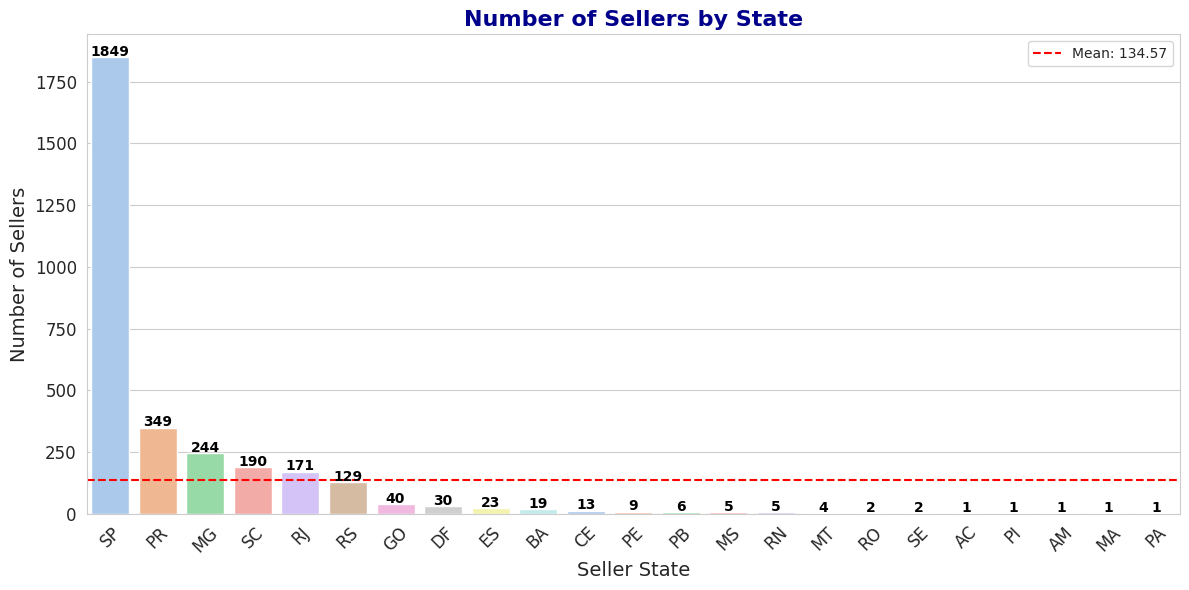

In [72]:
# Menghitung jumlah penjual per wilayah
bysellerstate_df = sellers_df.groupby(by="seller_state").seller_id.nunique().reset_index()
bysellerstate_df.rename(columns={
    "seller_id": "seller_count"
}, inplace=True)

# Mengatur ukuran grafik
plt.figure(figsize=(12, 6))

# Membuat bar plot
sns.set_style("whitegrid")
colors = sns.color_palette("pastel", len(bysellerstate_df))
bar_plot = sns.barplot(
    y="seller_count",
    x="seller_state",
    data=bysellerstate_df.sort_values(by="seller_count", ascending=False),
    palette=colors
)

# Menambahkan judul dan label
plt.title("Number of Sellers by State", loc="center", fontsize=16, fontweight='bold', color='darkblue')
plt.ylabel("Number of Sellers", fontsize=14)
plt.xlabel("Seller State", fontsize=14)
plt.xticks(rotation=45, fontsize=12)  # Memutar label pada sumbu x untuk keterbacaan
plt.tick_params(axis='y', labelsize=12)

# Menambahkan anotasi untuk setiap bar
for index, row in enumerate(bysellerstate_df.sort_values(by="seller_count", ascending=False).iterrows()):
    bar_plot.text(
        index,
        row[1]['seller_count'] + 5,  # Offset untuk menempatkan teks di atas bar
        row[1]['seller_count'],
        color='black',
        ha="center",
        fontsize=10,
        fontweight='bold'
    )

# Menambahkan garis horizontal pada rata-rata
mean_value = bysellerstate_df['seller_count'].mean()
plt.axhline(mean_value, color='red', linestyle='--', label=f'Mean: {mean_value:.2f}')

# Menampilkan legenda
plt.legend()

# Menampilkan grafik
plt.tight_layout()  # Untuk memastikan semua elemen pas di dalam area plot
plt.show()

### Pertanyaan 2: Berapa hari keterlambatan pengiriman untuk setiap order dalam 50 pesanan terakhir yang berhasil terkirim?

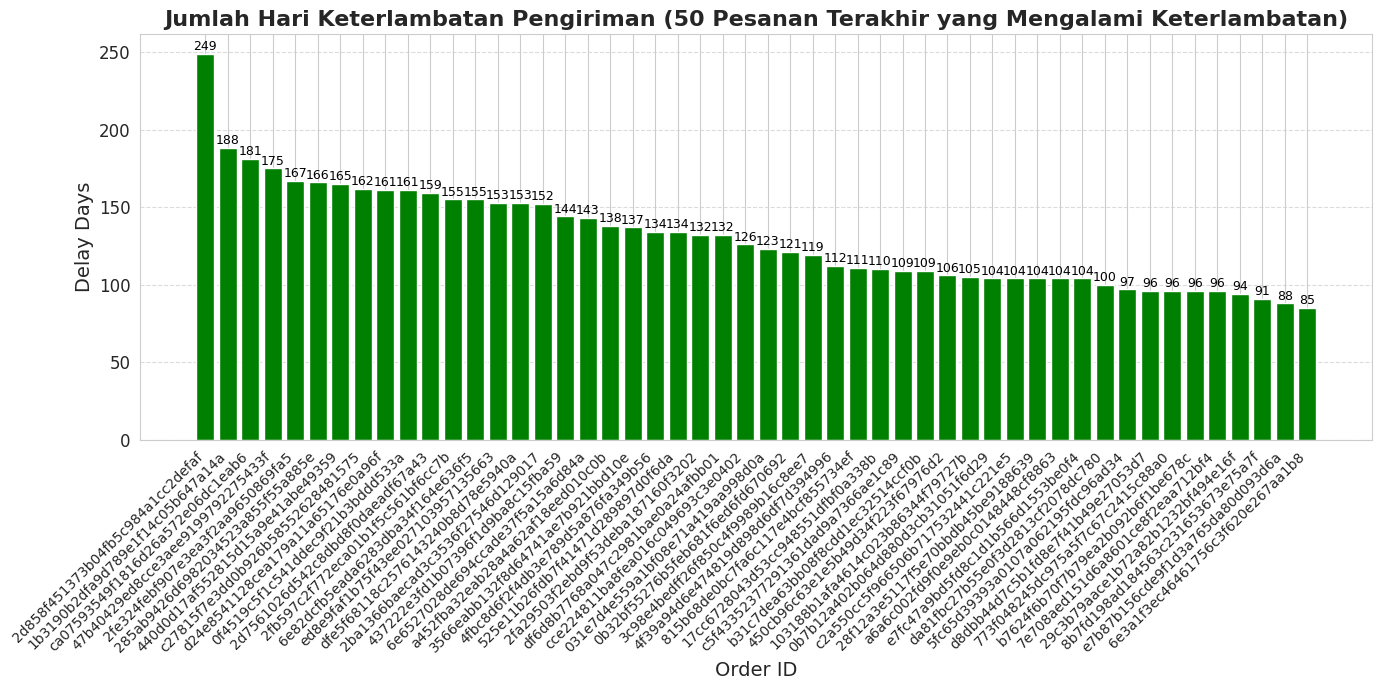

In [93]:
plt.figure(figsize=(14, 7))
bars = plt.bar(last_50_late_orders['order_id'].astype(str), last_50_late_orders['delay_days'], color='green')

# Menambahkan anotasi untuk setiap bar
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.5, int(yval), ha='center', va='bottom', fontsize=9, color='black')

# Menambahkan detail visual
plt.title('Jumlah Hari Keterlambatan Pengiriman (50 Pesanan Terakhir yang Mengalami Keterlambatan)', fontsize=16, fontweight='bold')
plt.xlabel('Order ID', fontsize=14)
plt.ylabel('Delay Days', fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.yticks(fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Menampilkan visualisasi
plt.tight_layout()
plt.show()

**Insight:**
- Visualisasi pertama menunjukkan variasi jumlah penjual di berbagai wilayah. Beberapa wilayah memiliki jumlah penjual yang jauh lebih tinggi dibandingkan yang lain, yang dapat mengindikasikan adanya konsentrasi pasar di wilayah tersebut.
- Wilayah dengan jumlah penjual tertinggi dapat dianggap sebagai pusat bisnis yang lebih aktif. Hal ini mungkin terkait dengan faktor ekonomi lokal, populasi yang lebih besar, atau infrastruktur yang lebih baik untuk mendukung kegiatan bisnis.
-Sebaliknya, wilayah dengan jumlah penjual paling sedikit mungkin menunjukkan peluang untuk meningkatkan kegiatan bisnis atau pemasaran. Ini dapat menjadi area fokus bagi strategi pengembangan pasar.
-Garis horizontal merah yang menunjukkan rata-rata jumlah penjual memberikan konteks tambahan. Wilayah dengan jumlah penjual di bawah rata-rata mungkin memerlukan perhatian lebih dalam hal pengembangan bisnis atau promosi untuk menarik lebih banyak penjual.
- Visualisasi kedua menunjukkan variasi jumlah hari keterlambatan pengiriman di antara 50 pesanan terakhir yang mengalami keterlambatan.
- Dengan melihat nilai tertinggi, kita dapat mengidentifikasi pesanan mana yang mengalami keterlambatan paling parah. Ini dapat membantu pereusahaan untuk fokus pada penyebab keterlambatan dalam pengiriman tertentu.
- Keterlambatan dalam pengiriman dapat berdampak langsung pada kepuasan pelanggan. Dengan mengenali order yang mengalami keterlambatan lebih dari batas yang dapat diterima, perusahaan dapat mengambil langkah proaktif untuk menginformasikan pelanggan dan mengelola ekspektasi mereka.

## Analisis Lanjutan (Opsional)

## Conclusion

- Hasil EDA dan visualisasi menunjukkan bahwa terdapat variasi yang signifikan dalam jumlah penjual di berbagai wilayah. Beberapa wilayah memiliki konsentrasi penjual yang lebih tinggi, sementara wilayah lain menunjukkan angka yang lebih rendah. Hal ini bisa mencerminkan kepadatan pasar, peluang bisnis, dan preferensi lokal yang berbeda di setiap wilayah. Wilayah-wilayah tertentu menunjukkan konsentrasi penjual yang lebih tinggi, yang dapat dihubungkan dengan faktor-faktor seperti infrastruktur, aksesibilitas pasar, dan tingkat urbanisasi. Misalnya, jika wilayah metropolitan memiliki lebih banyak penjual, ini mungkin mencerminkan tingginya permintaan dan potensi pasar. Wilayah dengan jumlah penjual yang lebih rendah dapat dianggap sebagai pasar potensial untuk ekspansi. Analisis lebih lanjut dapat dilakukan untuk memahami faktor-faktor yang mungkin menghambat pertumbuhan penjual di wilayah tersebut, seperti aksesibilitas, regulasi, atau kebutuhan infrastruktur. Berdasarkan distribusi penjual, perusahaan dapat merencanakan strategi pengembangan dan distribusi yang lebih baik, memperkuat hubungan dengan penjual di wilayah dengan potensi tinggi, dan mempertimbangkan inisiatif untuk mendukung pertumbuhan di wilayah yang kurang terlayani.
- Analisis menunjukkan bahwa terdapat variasi yang signifikan dalam jumlah hari keterlambatan pengiriman antar order. Beberapa pesanan mengalami keterlambatan yang cukup signifikan. Dari 50 pesanan terbaru yang mengalami keterlambatan paling lama yaitu 249 hari dan yang paling cepat mengalami keterlambatan 85 hari. Hal ini mencerminkan perbedaan dalam efisiensi pengiriman, yang dapat dipengaruhi oleh berbagai faktor seperti lokasi pengiriman, jenis produk, dan kebijakan logistik. Berdasarkan hasil analisis, perusahaan dapat merumuskan rekomendasi untuk meningkatkan efisiensi pengiriman. Misalnya, memperbaiki komunikasi dengan pihak ketiga dalam pengiriman, meninjau proses pemrosesan pesanan, atau menambah armada pengiriman untuk mengurangi keterlambatan

In [96]:
sellers_df.to_csv("sellers_data.csv", index=False)

In [97]:
orders_df.to_csv("orders_data.csv", index=False)